## <center>Assignment 2</center>

### <center>Part 1: HST Calibration Routine</center>

#### Name: Shreyas Dhumal
#### Student no: 26106049

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
%matplotlib widget

In [2]:
def load_raw_data(filepath, ext=1):
    """
    Loads the headers and data from a FITS file
    """
    with fits.open(filepath) as hdul:
        header = hdul[0].header
        data = hdul[ext].data
    return header, data

def print_image_stats(images_dict):
    """
    Goes through a dictionary of images to print their shapes and data types
    """
    for name, image in images_dict.items():
        print(f"\n{name}\nShape: {image.shape}\nData type: {image.dtype}")

def plot_image(data, title, pmin=1, pmax=99):
    image_data = data[0].copy() 
    vmin, vmax = np.percentile(image_data, [pmin, pmax])
    
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(image_data, origin='lower', vmin=vmin, vmax=vmax)
    ax.set_title(title)
    plt.show()


ubai2505m
Shape: (4, 800, 800)
Data type: >i2

ubai2507m
Shape: (4, 800, 800)
Data type: >i2

ubai2508m
Shape: (4, 800, 800)
Data type: >i2


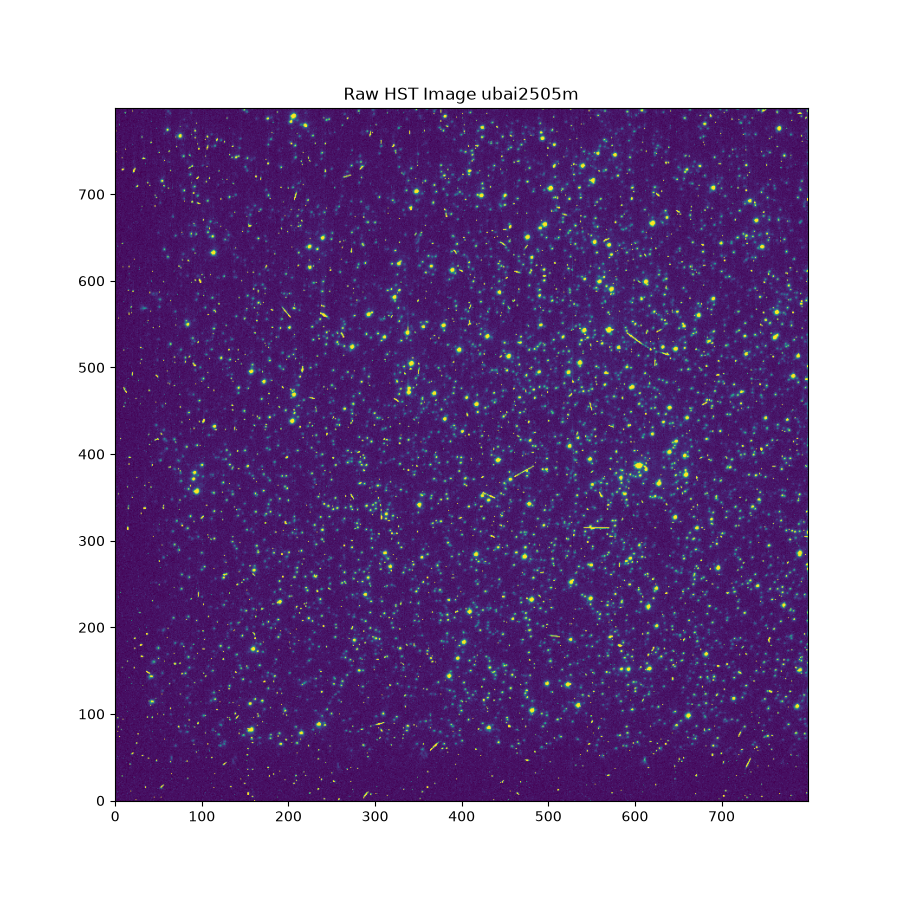

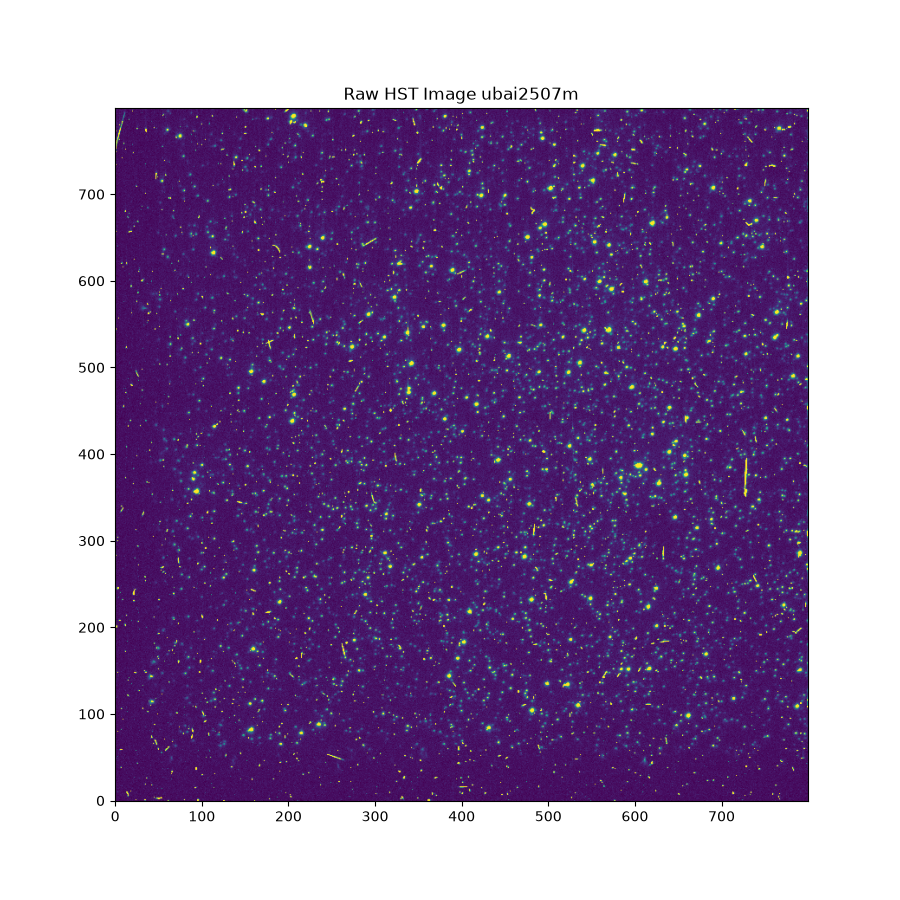

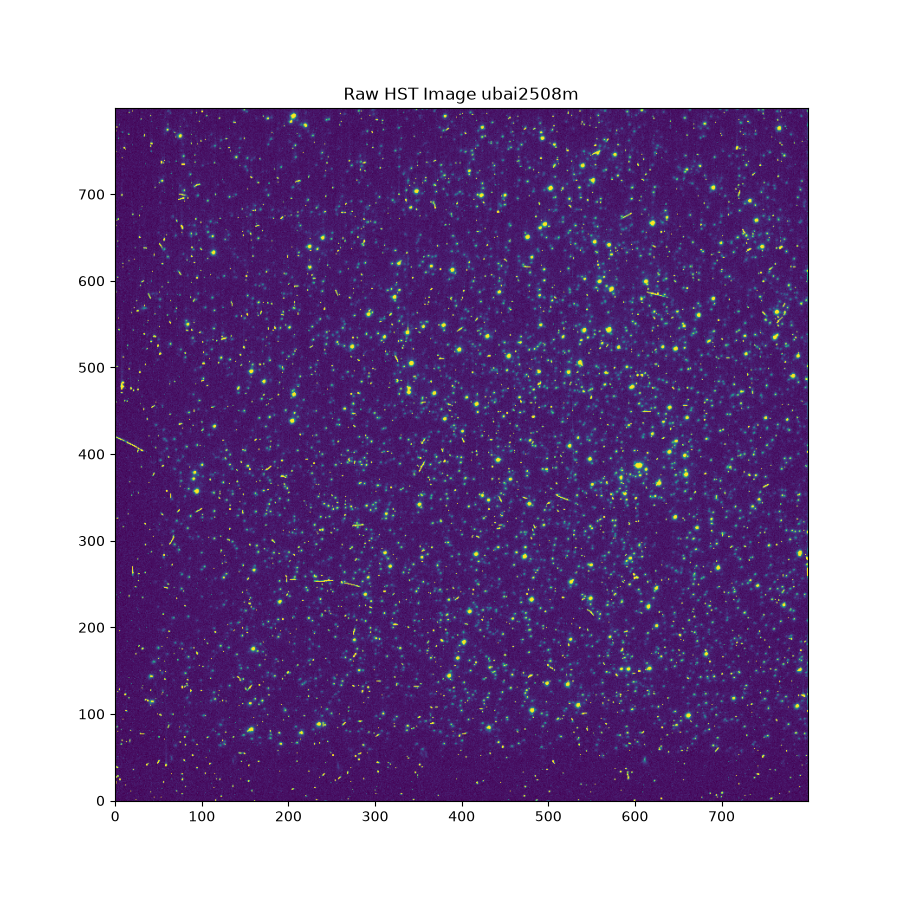

In [3]:
# file_paths = {
#     "ubai2505m": 'calibration/ubai2505m/ubai2505m_raw.fits',
#     "ubai2507m": 'calibration/ubai2507m/ubai2507m_raw.fits',
#     "ubai2508m": 'calibration/ubai2508m/ubai2508m_raw.fits'
# }

# raw_data = {}
# for name, path in file_paths.items():
#     header, data = load_raw_data(path, ext=1) 
#     raw_data[name] = data

files_dict = {
    "ubai2505m": {"path": 'hst-calibration/ubai2505m/ubai2505m_raw.fits', "ext": 1},
    "ubai2507m": {"path": 'hst-calibration/ubai2507m/ubai2507m_raw.fits', "ext": 0},
    "ubai2508m": {"path": 'hst-calibration/ubai2508m/ubai2508m_raw.fits', "ext": 1}
}

raw_data = {}
for name, path in files_dict.items():
    header, data = load_raw_data(path["path"], ext=path["ext"])
    raw_data[name] = data

print_image_stats(raw_data)

plt.close('all')
for name, data in raw_data.items():
    plot_image(data, title=f"Raw HST Image {name}")

### Maskfile 

In [4]:
# we need fits to get the data
def load_mask_data(filepath):
    """
    Loads data from a mask FITS file
    """
    return fits.getdata(filepath)

In [5]:
def plot_raw_mask(mask_array, title):
    """
    Plots the raw mask image with a colorbar to visualize defect values
    """
    fig, ax = plt.subplots(figsize=(9, 9))
    im = ax.imshow(mask_array, origin="lower", cmap="gray", interpolation='nearest')
    fig.colorbar(im, ax=ax, label="Mask value", shrink=0.95, fraction=0.045, pad=0.03)
    ax.set_title(title)
    plt.show()

mask_file_paths = {
    "u2505_mask": 'hst-calibration/ubai2505m/ubai2505m_maskfile.fits',
    "u2507_mask": 'hst-calibration/ubai2507m/ubai2507m_maskfile.fits',
    "u2508_mask": 'hst-calibration/ubai2508m/ubai2508m_maskfile.fits'
}

mask_data = {}

for name, path in mask_file_paths.items():
    data = load_mask_data(path)
    mask_data[name] = data

print_image_stats(mask_data)



u2505_mask
Shape: (4, 800, 800)
Data type: >i2

u2507_mask
Shape: (4, 800, 800)
Data type: >i2

u2508_mask
Shape: (4, 800, 800)
Data type: >i2


In [6]:
# Plot for ubai2505m file
# https://www.geeksforgeeks.org/python/matplotlib-pyplot-imshow-in-python/

# plt.close('all')
# plot_raw_mask(maskplot_u2505, "Maskfile ubai2505m")

Text(0.5, 1.0, 'Masked Values plot ubai2505m')

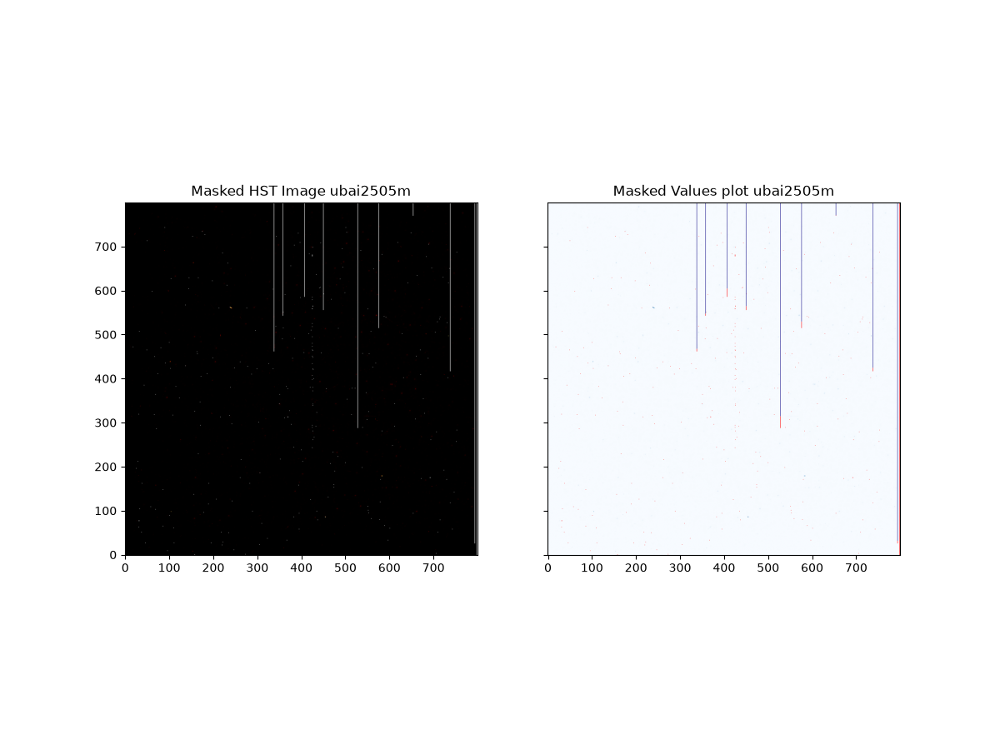

In [7]:
maskplot_u2505 = mask_data["u2505_mask"][0].copy()
maskplot_u2507 = mask_data["u2507_mask"][0].copy()
maskplot_u2508 = mask_data["u2508_mask"][0].copy()
pc_data_u2505 = raw_data["ubai2505m"][0].copy()

flag1 = maskplot_u2505 == 0
flag2 = maskplot_u2505 == 2
flag3 = maskplot_u2505 == 256

combined_flag = flag2 | flag3
masked_image_u2505 = np.ma.masked_where(combined_flag, pc_data_u2505)

plt.close('all')
vmin = masked_image_u2505.min()
vmax = masked_image_u2505.max()
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 9), sharex=True, sharey=True)
ax1.imshow(masked_image_u2505, origin='lower',cmap="afmhot", vmin=vmin, vmax=vmax)
ax1.set_title("Masked HST Image ubai2505m")

ax2.imshow(pc_data_u2505, origin='lower', cmap='Blues')
ax2.imshow(np.ma.masked_where(maskplot_u2505 != 2, maskplot_u2505 == 2), origin='lower', cmap='autumn')
ax2.imshow(np.ma.masked_where(maskplot_u2505 != 256, maskplot_u2505 == 256), origin='lower', cmap='plasma')
ax2.set_title("Masked Values plot ubai2505m")

The vertical lines in the image appear to be charge bleeding artifacts from the CCD detector. These occur when bright stars or cosmic rays cause pixels to become saturated, making excess charge spread along the image columns. The mask file marks these affected pixels with data quality flags (2 and 256), indicating that their values may not be reliable. </br>
Reference: http://stardial.astro.illinois.edu/cosmics.html

### BLEVFILE

In [8]:
# blevfile_u2505 = fits.getdata('calibration/ubai2505m/ubai2505m_blevfile.fits')
# blevfile_u2507 = fits.getdata('calibration/ubai2507m/ubai2507m_blevfile.fits')
# blevfile_u2508 = fits.getdata('calibration/ubai2508m/ubai2508m_blevfile.fits')

In [9]:
def parse_blev_file(filename, chip=0):
    with fits.open(filename) as hdul:
        data = hdul[chip].data
        
        overscan = data[9:790, 8:14]     # As overscan region is in columns 9-14 and rows 10-790.
        pbias_odd = np.mean(overscan[:, 0::2])    # PBIASODD is the odd columns (9, 11, and 13)
        pbias_even = np.mean(overscan[:, 1::2])   # BIASEVEN is the even columns (8, 10, and 12)
        
        return pbias_odd, pbias_even

def apply_bias_corr(raw_chip_data, odd_mean, even_mean):
    corrected_data = raw_chip_data.copy().astype(float)
    corrected_data[:, 0::2] -= odd_mean
    corrected_data[:, 1::2] -= even_mean
    
    return corrected_data

In [10]:
with fits.open('hst-calibration/ubai2505m/ubai2505m_raw.fits') as hdul:
    raw_data = hdul[1].data

blev_file_path = 'hst-calibration/ubai2505m/ubai2505m_blevfile.fits'
odd_mean, even_mean = parse_blev_file(blev_file_path, chip=1)

print(f" Bias Level Odd: {odd_mean}, Bias Level Even: {even_mean}")

blev_corrected = apply_bias_corr(raw_data, odd_mean, even_mean)


 Bias Level Odd: 299.58472044387537, Bias Level Even: 299.59154929577466


### BIASFILE

In [11]:
# biasfile_u2505 = fits.getdata('calibration/ubai2505m/ubai2505m_biasfile.fits')
# biasfile_u2507 = fits.getdata('calibration/ubai2507m/ubai2507m_biasfile.fits')
# biasfile_u2508 = fits.getdata('calibration/ubai2508m/ubai2508m_biasfile.fits')

In [12]:
def load_bias_data(filepath):
    """
    Loads data from a BIAS file
    """
    return fits.getdata(filepath)

In [14]:
bias_file_paths = {
    "u2505_biasfile": 'hst-calibration/ubai2505m/ubai2505m_biasfile.fits',
    "u2507_biasfile": 'hst-calibration/ubai2507m/ubai2507m_biasfile.fits',
    "u2508_biasfile": 'hst-calibration/ubai2508m/ubai2508m_biasfile.fits'
}
bias_data = {}

for name, path in bias_file_paths.items():
    data = load_bias_data(path)
    bias_data[name] = data

print_image_stats(bias_data)



u2505_biasfile
Shape: (4, 800, 800)
Data type: >f4

u2507_biasfile
Shape: (4, 800, 800)
Data type: >f4

u2508_biasfile
Shape: (4, 800, 800)
Data type: >f4


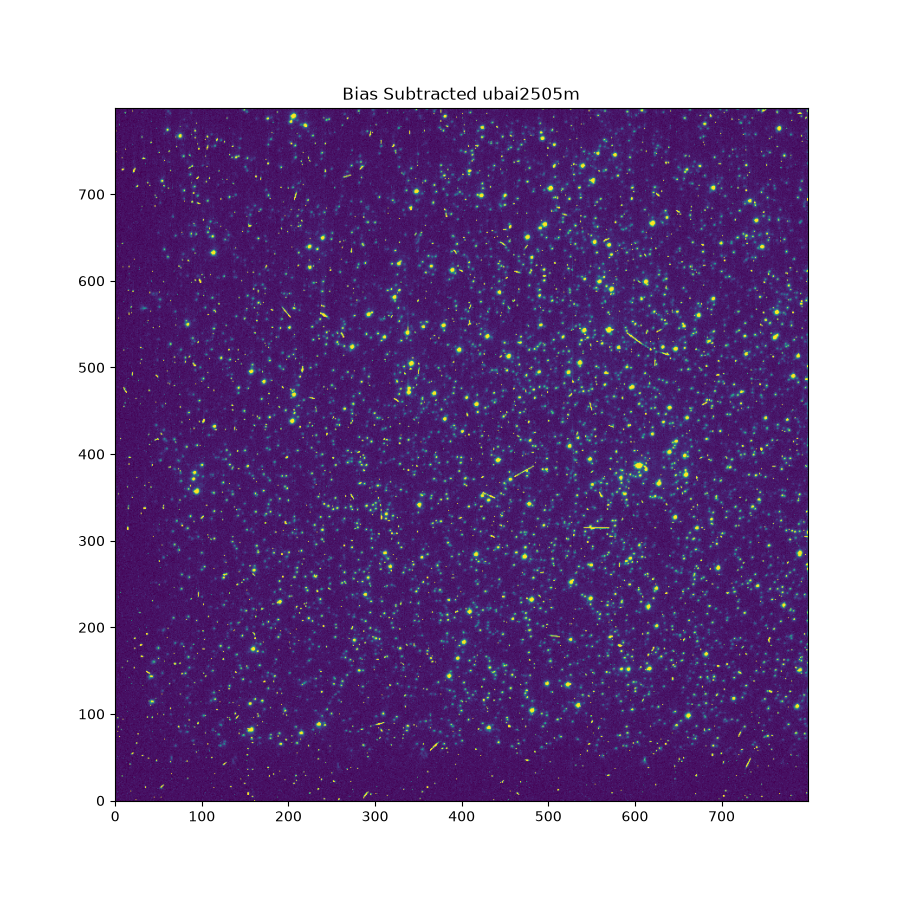

In [15]:
def subtract_bias_data(blev_corrected_image, bias_file):
    """
    Subtracts the  bias data from the BLEV-corrected image
    """
    return blev_corrected_image - bias_file

bias_subtracted_u2505 = subtract_bias_data(blev_corrected, bias_data["u2505_biasfile"])
bias_subtracted_u2507 = subtract_bias_data(blev_corrected, bias_data["u2507_biasfile"])
bias_subtracted_u2508 = subtract_bias_data(blev_corrected, bias_data["u2508_biasfile"])

plt.close('all')
plot_image(bias_subtracted_u2505, title="Bias Subtracted ubai2505m", pmin=1, pmax=99)  
# used same fucntion for plotting from raw image plot function


### DARKFILE

In [16]:
def load_dark_data(filepath):
    """
    Loads data from a DARK file
    """
    return fits.getdata(filepath)

In [17]:
dark_file_paths = {
    "u2505_darkfile": 'hst-calibration/ubai2505m/ubai2505m_darkfile.fits',
    "u2507_darkfile": 'hst-calibration/ubai2507m/ubai2507m_darkfile.fits',
    "u2508_darkfile": 'hst-calibration/ubai2508m/ubai2508m_darkfile.fits'
}
dark_data = {}

for name, path in dark_file_paths.items():
    data = load_dark_data(path)
    dark_data[name] = data

print_image_stats(dark_data)


u2505_darkfile
Shape: (4, 800, 800)
Data type: >f4

u2507_darkfile
Shape: (4, 800, 800)
Data type: >f4

u2508_darkfile
Shape: (4, 800, 800)
Data type: >f4


In [18]:
# Reference:
# https://stackoverflow.com/questions/46455109/printing-the-header-of-a-fits-file-with-astropy-nameerror-name-header-is-not

# with fits.open('calibration/ubai2505m/ubai2505m_darkfile.fits') as hdulist: 
#      hdulist.info()
#      for hdu in hdulist:
#          print(repr(hdu.header))

In [19]:
# Exacting exptime from file 
# for Darkfile_u2505
header_u2505, file_data_u2505 = load_raw_data('hst-calibration/ubai2505m/ubai2505m_raw.fits', ext=0)
exptime_u2505 = header_u2505['EXPTIME']
print("exposure time of Darkfile_u2505:",exptime_u2505)

# for Darkfile_u2507
header_u2507, file_data_u2507 = load_raw_data('hst-calibration/ubai2507m/ubai2507m_raw.fits', ext=0)
exptime_u2507 = header_u2507['EXPTIME']
print("exposure time of Darkfile_u2507:",exptime_u2507)

# for Darkfile_u2508
header_u2508, file_data_u2508 = load_raw_data('hst-calibration/ubai2508m/ubai2508m_raw.fits', ext=0)
exptime_u2508 = header_u2508['EXPTIME']
print("exposure time of Darkfile_u2508:",exptime_u2508)

exposure time of Darkfile_u2505: 700.0
exposure time of Darkfile_u2507: 700.0
exposure time of Darkfile_u2508: 600.0


In [20]:
def subtract_dark_data(bias_subtracted_image, dark_file, exptime):
    """
    Scales the dark file data by the exposure time and then subtracts it from the bias-corrected image
    """
    return bias_subtracted_image - (dark_file * exptime)

dark_subtracted_u2505 = subtract_dark_data(bias_subtracted_u2505, dark_data["u2505_darkfile"], exptime_u2505)
dark_subtracted_u2507 = subtract_dark_data(bias_subtracted_u2507, dark_data["u2507_darkfile"], exptime_u2507)
dark_subtracted_u2508 = subtract_dark_data(bias_subtracted_u2508, dark_data["u2508_darkfile"], exptime_u2508)


Text(0.5, 1.0, 'Dark Subtracted ubai2505m')

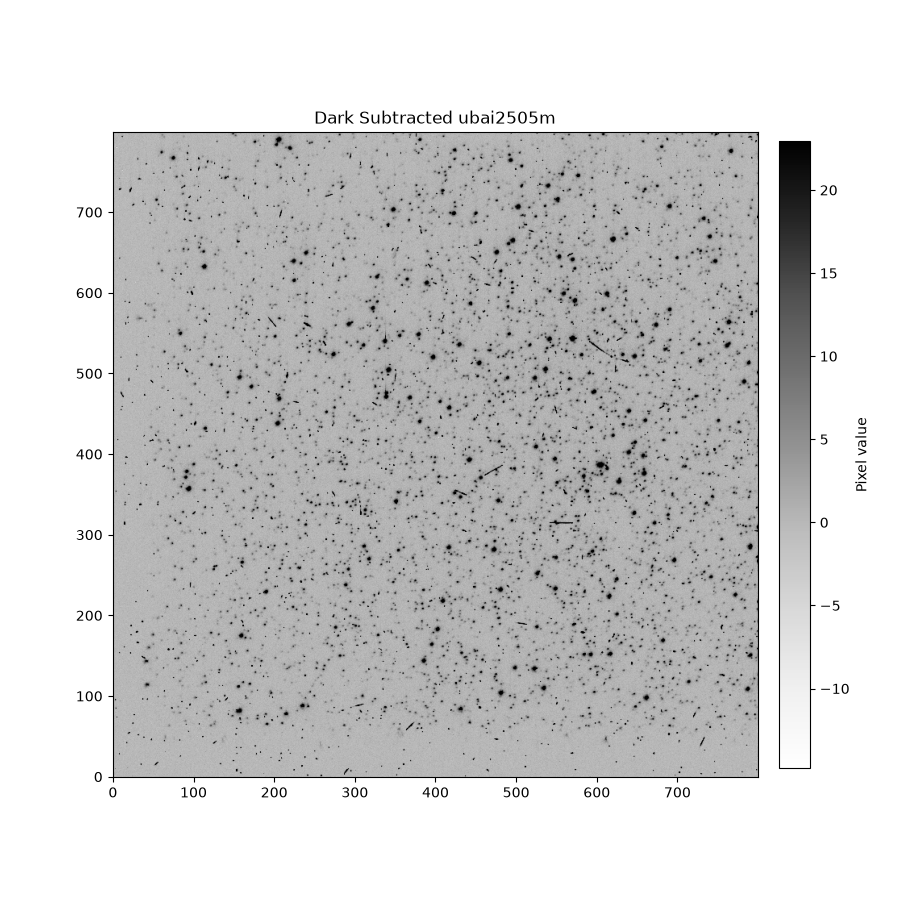

In [21]:
plt.close('all')

darksub_plot_u2505 = dark_subtracted_u2505[0].copy()
fig, ax = plt.subplots(figsize=(9, 9))
pmin = 0
pmax = 99
vmin, vmax = np.percentile(darksub_plot_u2505, [pmin, pmax])
disp_img = ax.imshow(darksub_plot_u2505, origin="lower",cmap='Grays',vmin=vmin,vmax=vmax)
fig.colorbar(disp_img, label="Pixel value",shrink=0.95, fraction=0.045, pad=0.03)
ax.set_title("Dark Subtracted ubai2505m")

### FLATFILE

In [22]:
# flatfile_u2505 = fits.getdata('calibration/ubai2505m/ubai2505m_flatfile.fits')
# flatfile_u2507 = fits.getdata('calibration/ubai2507m/ubai2507m_flatfile.fits')
# flatfile_u2508 = fits.getdata('calibration/ubai2508m/ubai2508m_flatfile.fits')

In [23]:
def load_flatfile_data(filepath):
    """
    Loads data from a Flat file
    """
    return fits.getdata(filepath)

In [24]:
flat_file_paths = {
    "u2505_flatfile": 'hst-calibration/ubai2505m/ubai2505m_flatfile.fits',
    "u2507_flatfile": 'hst-calibration/ubai2507m/ubai2507m_flatfile.fits',
    "u2508_flatfile": 'hst-calibration/ubai2508m/ubai2508m_flatfile.fits'
}

flatfile_data = {}

for name, path in flat_file_paths.items():
    data = load_flatfile_data(path)
    flatfile_data[name] = data

print_image_stats(flatfile_data)


u2505_flatfile
Shape: (4, 800, 800)
Data type: >f4

u2507_flatfile
Shape: (4, 800, 800)
Data type: >f4

u2508_flatfile
Shape: (4, 800, 800)
Data type: >f4


In [25]:
def apply_flat_correction(dark_subtracted_image, flat_file):
    """
    Multiplies the dark-subtracted image by the flat field
    """
    return dark_subtracted_image * flat_file

flat_corrected_u2505 = apply_flat_correction(dark_subtracted_u2505, flatfile_data["u2505_flatfile"])
flat_corrected_u2507 = apply_flat_correction(dark_subtracted_u2507, flatfile_data["u2507_flatfile"])
flat_corrected_u2508 = apply_flat_correction(dark_subtracted_u2508, flatfile_data["u2508_flatfile"])

In [26]:
print(flat_corrected_u2505.shape)

(4, 800, 800)


In [27]:
# bad_pixels = (maskplot_u2505 != 0)
# mean_sky, median_sky, stand_div_sky = sigma_clipped_stats(flat_corrected_u2505[100:750, 100:750],  mask=bad_pixels[100:750, 100:750],  sigma=3.0, maxiters=5)

def sky_background(flat_image, mask_image, sigma=3.0, maxiters=10):
    """
    Calculates sky on the central chip region using sigma clipping
    """
    bad_pixels = (mask_image != 0)
    mean_sky, median_sky, stand_div_sky = sigma_clipped_stats(flat_image[100:750, 100:750],  mask=bad_pixels[100:750, 100:750],  sigma=sigma, maxiters=maxiters)
    return median_sky, stand_div_sky

def subtract_sky_background(flat_corr_image, median_sky):
    """
    Subtracts the median sky background from the flat corrected image
    """
    return flat_corr_image - median_sky

In [28]:
median_sky_u2505, stand_div_sky_2505 = sky_background(flat_corrected_u2505[0], maskplot_u2505)
median_sky_u2507, stand_div_sky_2507 = sky_background(flat_corrected_u2507[0], maskplot_u2507)
median_sky_u2508, stand_div_sky_2508 = sky_background(flat_corrected_u2508[0], maskplot_u2508)

print(f"Sky background_u2505: {median_sky_u2505:.4f}, Standard deviation_u2505: {stand_div_sky_2505:.4f}")
print(f"Sky background_u2507: {median_sky_u2507:.4f}, Standard deviation_u2507: {stand_div_sky_2507:.4f}")
print(f"Sky background_u2508: {median_sky_u2508:.4f}, Standard deviation_u2508: {stand_div_sky_2508:.4f}")

Sky background_u2505: 0.7565, Standard deviation_u2505: 0.7977
Sky background_u2507: 0.7565, Standard deviation_u2507: 0.7977
Sky background_u2508: 0.8110, Standard deviation_u2508: 0.7979


In [29]:
calibrated_image_u2505 = subtract_sky_background(flat_corrected_u2505, median_sky_u2505)
calibrated_image_u2507 = subtract_sky_background(flat_corrected_u2507, median_sky_u2507)
calibrated_image_u2508 = subtract_sky_background(flat_corrected_u2508, median_sky_u2507)

In [30]:
print(calibrated_image_u2505[0].shape)

(800, 800)


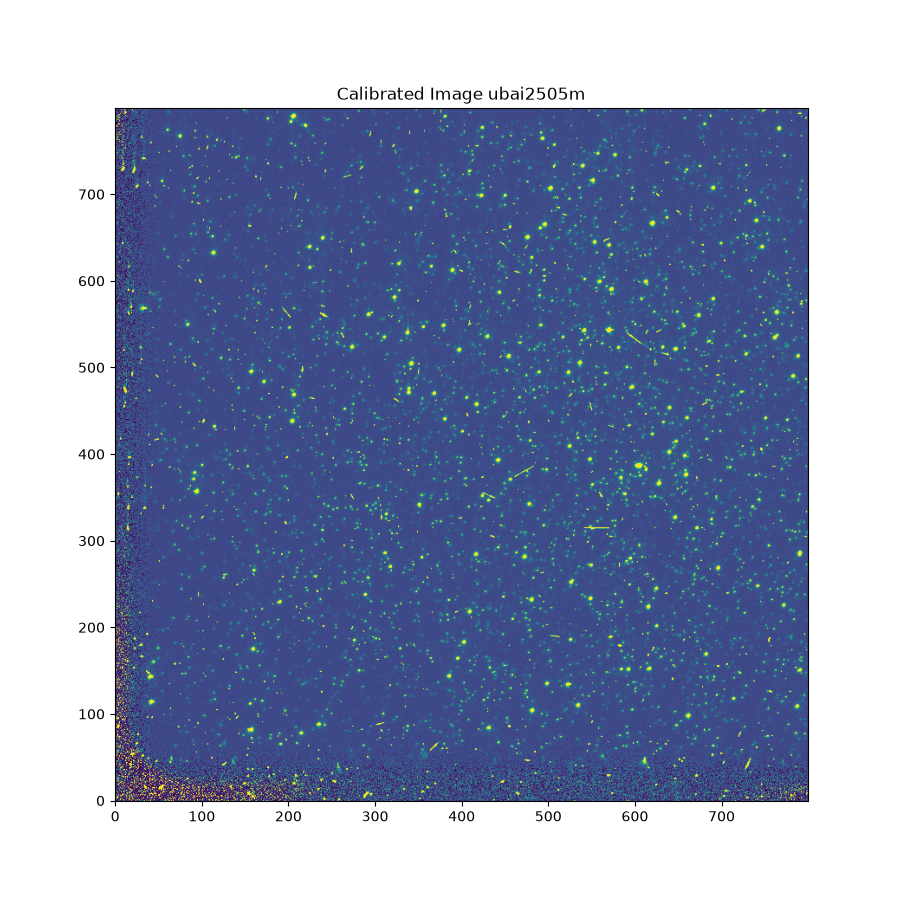

In [31]:
plt.close('all')
plot_image(calibrated_image_u2505, title="Calibrated Image ubai2505m", pmin=1, pmax=99)

### Photometric Calibration

In [32]:
header_c0m_ubai2505, data_c0m_ubai2505 = load_raw_data('hst-processed/ubai2505m_c0m_aligned.fits', ext=0)
exptime_ubai2505 = header_c0m_ubai2505['EXPTIME']

header_c0m_ubai2507, data_c0m_ubai2507 = load_raw_data('hst-processed/ubai2507m_c0m_aligned.fits', ext=0)
exptime_ubai2507 = header_c0m_ubai2507['EXPTIME']

header_c0m_ubai2508, data_c0m_ubai2508 = load_raw_data('hst-processed/ubai2508m_c0m_aligned.fits', ext=0)
exptime_ubai2508 = header_c0m_ubai2508['EXPTIME']


photflam = 1.115396e-16
photzpt = -21.1
photplam = 3359.474
photbw = 204.4908
zp_corr = -0.03288031

In [33]:
def calculate_flux(calibrated_image, exptime, photflam):
    """
    Converts Calibrated image from total counts to flux (erg / s / cm^2 / Angstrom)
    """
    count_rate = calibrated_image / exptime
    return count_rate * photflam

def calculate_st_magnitude(photflam, photzpt, zp_corr):
    """
    Calculate ST magnitude for the specific filter and contamination correction
    """
    return -2.5 * np.log10(photflam) + photzpt + zp_corr

flux_image_u2505 = calculate_flux(calibrated_image_u2505[0], exptime_ubai2505, photflam)
flux_image_u2507 = calculate_flux(calibrated_image_u2507[0], exptime_ubai2507, photflam)
flux_image_u2508 = calculate_flux(calibrated_image_u2508[0], exptime_ubai2508, photflam)

st_mag_zeropoint = calculate_st_magnitude(photflam, photzpt, zp_corr)
print(f"ST Magnitude Zero Point: {st_mag_zeropoint:.4f}")

ST Magnitude Zero Point: 18.7485


In [34]:
# count_rate = calibrated_image_u2505[0] / exptime
# flux_image = count_rate * photflam    # unit: erg s^-1 cm^-2 Angstrom^-1
# st_magnitude = -2.5 * np.log10(photflam) + photzpt + zp_corr
# print("ST magnitude:", st_magnitude)

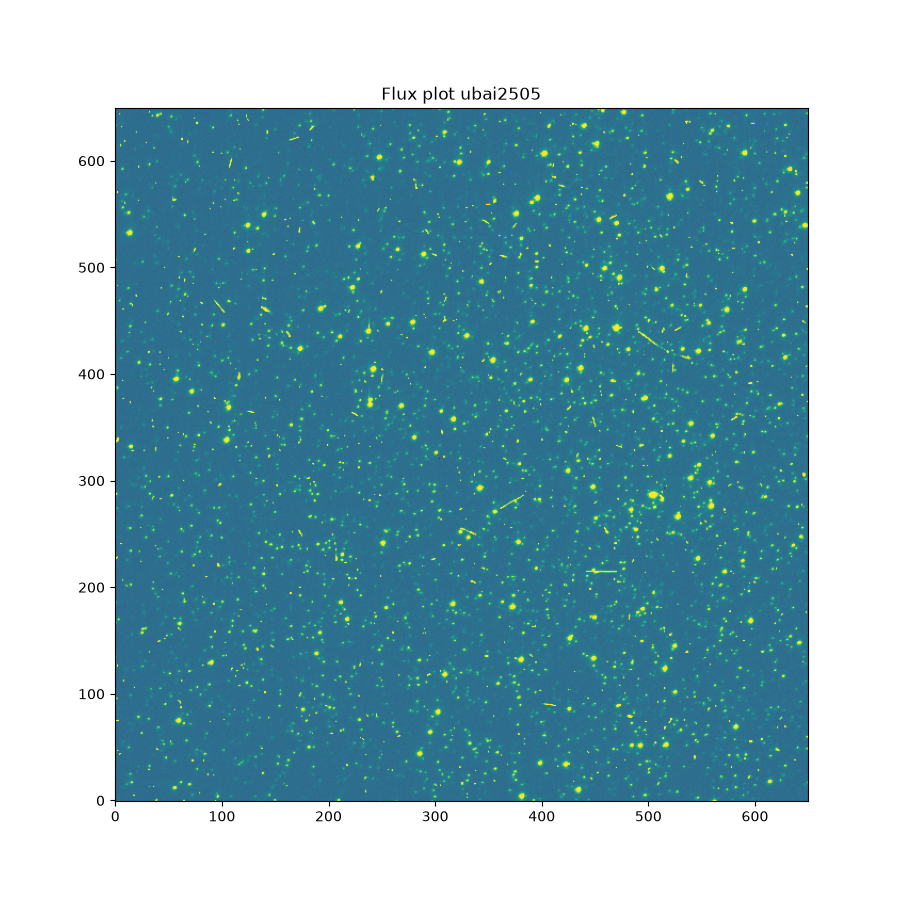

In [35]:
plt.close('all')
plot_image([flux_image_u2505[100:750, 100:750]],  title="Flux plot ubai2505",  pmin=0, pmax=99)

## Compare and Contrast

In [37]:
reference_file_u2505 = fits.getdata('hst-processed/ubai2505m_c0m_aligned.fits')
calibrate_file_u2505 = calibrated_image_u2505[0].copy()
# with fits.open('hst-processed/ubai2505m_c0m_aligned.fits') as hdulist: 
#     hdulist.info()
#     for hdu in hdulist:
#         print(repr(hdu.header))

print("Calibrated image shape:", calibrate_file_u2505.shape)
print("Reference image shape:", np.shape(reference_file_u2505))

Calibrated image shape: (800, 800)
Reference image shape: (800, 800)


### Visual Comparison

Text(0.5, 1.0, 'Reference HST Image ubai2505m')

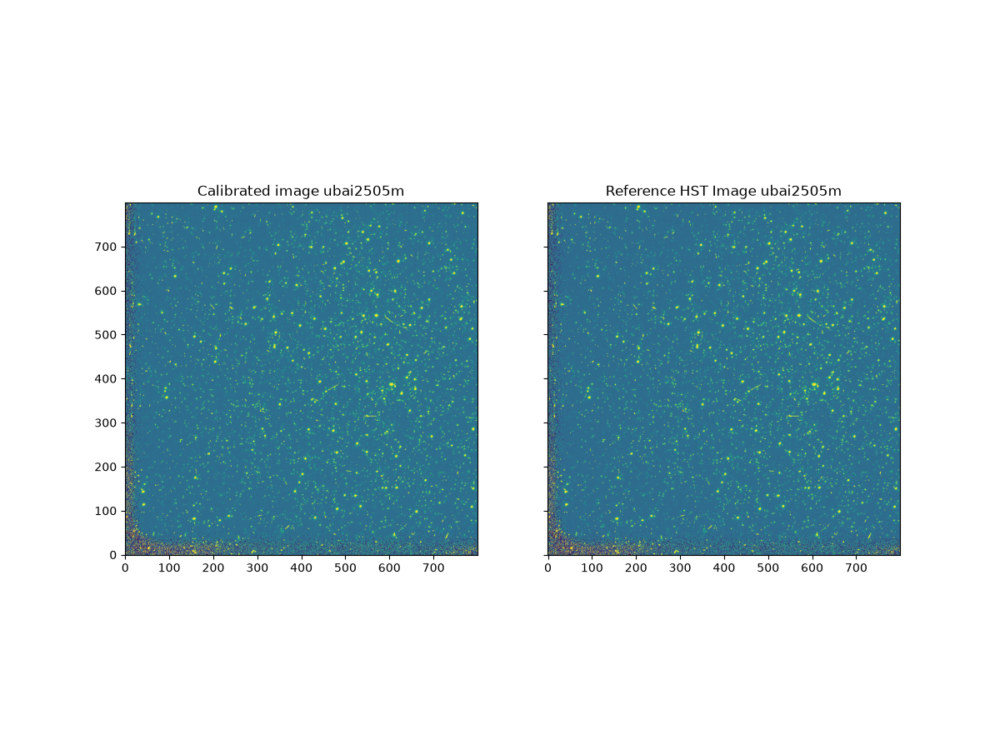

In [38]:
plt.close('all')
pmin = 0
pmax = 99
vmin1, vmax1 = np.percentile(calibrate_file_u2505[100:750, 100:750], [pmin, pmax])
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 9), sharex=True, sharey=True)
ax1.imshow(calibrate_file_u2505, origin='lower', vmin=vmin1, vmax=vmax1)
ax1.set_title("Calibrated image ubai2505m")


vmin2, vmax2 = np.percentile(reference_file_u2505[100:750, 100:750], [pmin, pmax])
ax2.imshow(reference_file_u2505, origin='lower', vmin=vmin2, vmax=vmax2)
ax2.set_title("Reference HST Image ubai2505m")

#### AI Useage:
To get good techniques on  quantitative analysis,I have used Google Gemini for initial research. Also, I have used this to identify some errors along the steps for example error's in matching data (4,800,800). </br>
Prompt for quantitative analysis: </br>
I have calibrated a raw HST FITS image and need to do quantitative analysis to compare my final calibrated image against an official science ready pipeline image. What are some standard methods or techniques I can use to compare these two images? Follow the guidelines of AI useage given in this webstie: https://aiassessmentscale.com/
</br> </br>
With this prompt it suggested to comapre using residual statistics, histograms, cross-sectional profiles, and percentage error; of which I have shown first two. 

### Residual Statistics

In [39]:
calibrated_file = calibrated_image_u2505[0].copy()
reference_file = reference_file_u2505.copy()

print("Calibrated image shape:", calibrated_file.shape)
print("Reference image shape:", reference_file.shape)

Calibrated image shape: (800, 800)
Reference image shape: (800, 800)


In [40]:
reference_flux = reference_file * photflam
residual = reference_flux - flux_image_u2505

print("Residual statistics")
print("-------------------")
print("Mean:", np.mean(residual))
print("Median:", np.median(residual))
print("Standard deviation:", np.std(residual))

Residual statistics
-------------------
Mean: 2.573483203573878e-16
Median: 8.081917791552098e-17
Standard deviation: 4.567299888581671e-15


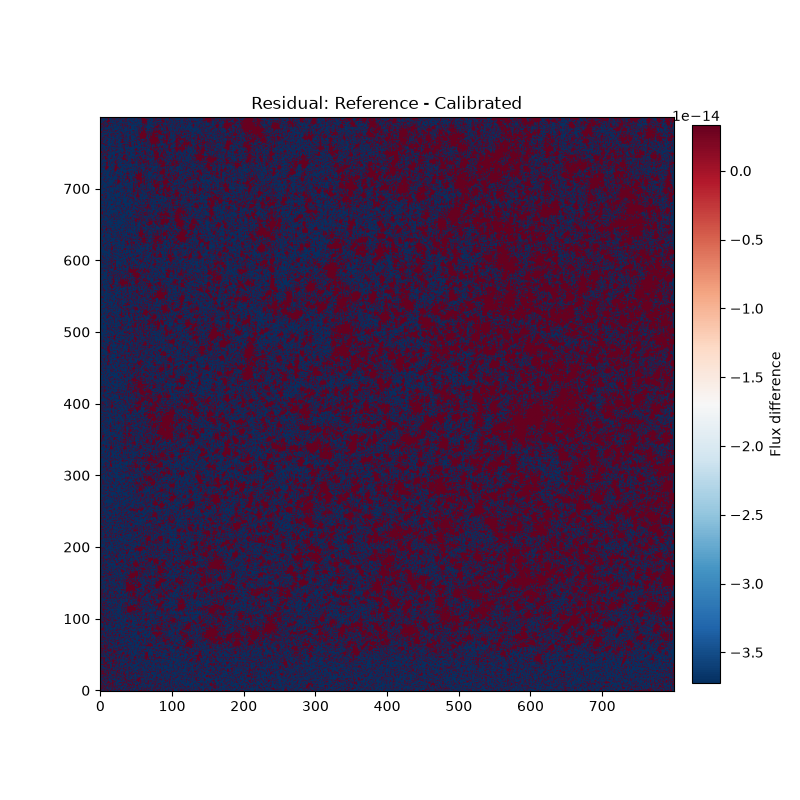

In [41]:
plt.close('all')

fig, ax = plt.subplots(figsize=(8, 8))
pmin = 0
pmax = 99
vmin, vmax = np.percentile(residual, [pmin, pmax])
residual_image = ax.imshow(calibrated_file, origin='lower',cmap='RdBu_r', vmin=vmin, vmax=vmax)
ax.set_title("Residual: Reference - Calibrated")
plt.colorbar(residual_image, ax=ax, label="Flux difference",shrink=0.95, fraction=0.045, pad=0.03)

#### Interpretation 
These values of Mean, Median, and Standard Deviation are close to zero which suggests negligible pixel-level differences. 

### Histogram comparison

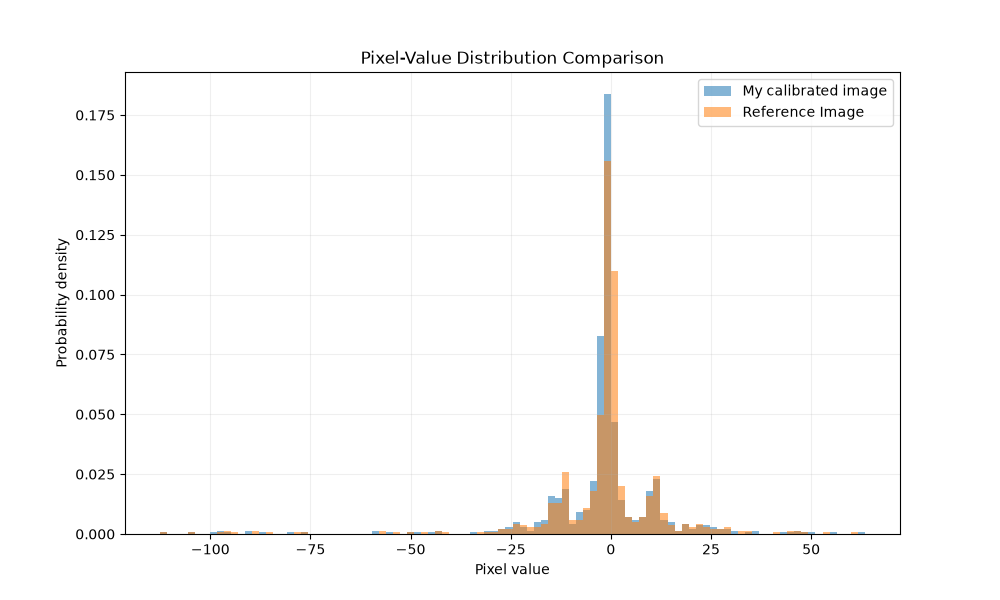

In [42]:
all_values = np.concatenate([calibrated_file[0], reference_file[0]])
pmin = 0
pmax = 99
vmin, vmax = np.percentile(all_values, [pmin, pmax])
bins = np.linspace(vmin, vmax, 101)

plt.figure(figsize=(10, 6))

plt.hist(calibrated_file[0],bins=bins,alpha=0.55,label="My calibrated image",density=True)
plt.hist(reference_file[0],bins=bins,alpha=0.55,label="Reference Image",density=True)

plt.xlabel("Pixel value")
plt.ylabel("Probability density")
plt.title("Pixel-Value Distribution Comparison")
plt.legend()
plt.grid(alpha=0.2)

#### Interpretation 
The pixel values of histograms showed broadly similar distributions. Overall, the residual statistics suggests close numerical agreement between the two images.